# 🏠 House Price Prediction (Boston Housing Dataset)

**Goal:** Predict the price of a house using its features (rooms, crime rate, distance to jobs, etc.).

This is a **regression** problem because the output (price) is a number, not a category like spam/ham.

**Steps we will follow**
1. Load the dataset
2. Explore the data (distributions, correlation)
3. Split into train and test sets
4. Handle missing data
5. Normalization (scaling)
6. Train a Linear Regression model
7. Evaluate with MSE (and RMSE, MAE, R²)
8. Predict the price of new houses

## Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Libraries imported successfully")

Libraries imported successfully


## Step 2: Load the Dataset

In [2]:
df = pd.read_csv("HousingData.csv")
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


In [3]:
print("Rows and columns:", df.shape)

Rows and columns: (506, 14)


### What do the columns mean?

| Column | Meaning | Type |
|---|---|---|
| CRIM | Crime rate in the town | Location |
| ZN | % of land for big residential plots | Location |
| INDUS | % of business (non-retail) land | Location |
| CHAS | Near Charles River? (1 = yes, 0 = no) | Location |
| NOX | Air pollution level | Location |
| **RM** | **Average number of rooms per house** | **Size** |
| AGE | % of old houses (built before 1940) | House |
| DIS | Distance to employment centres | Location |
| RAD | Access to highways | Location |
| TAX | Property tax rate | Location |
| PTRATIO | Students per teacher in the area | Location |
| B | A demographic index of the town | Location |
| LSTAT | % of lower-income people in the area | Location |
| **MEDV** | **House price in $1000s (this is our TARGET)** | Target |

**About the task words:** this dataset has no direct "bedrooms" column. `RM` (average rooms) is the closest thing
to house size. All the other columns describe the **location** of the house.

## Step 3: Explore the Data (EDA)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     486 non-null    float64
 1   ZN       486 non-null    float64
 2   INDUS    486 non-null    float64
 3   CHAS     486 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      486 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    int64  
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    486 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [5]:
df.describe()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,486.000000,486.000000,486.000000,486.000000,506.000000,506.000000,486.000000,506.000000,506.000000,506.000000,506.000000,506.000000,486.000000,506.000000
mean,3.611874,11.211934,11.083992,0.069959,0.554695,6.284634,68.518519,3.795043,9.549407,408.237154,18.455534,356.674032,12.715432,22.532806
std,8.720192,23.388876,6.835896,0.255340,0.115878,0.702617,27.999513,2.105710,8.707259,168.537116,2.164946,91.294864,7.155871,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.081900,0.000000,5.190000,0.000000,0.449000,5.885500,45.175000,2.100175,4.000000,279.000000,17.400000,375.377500,7.125000,17.025000
50%,0.253715,0.000000,9.690000,0.000000,0.538000,6.208500,76.800000,3.207450,5.000000,330.000000,19.050000,391.440000,11.430000,21.200000
75%,3.560263,12.500000,18.100000,0.000000,0.624000,6.623500,93.975000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


**Observation:** `count` is 506 for some columns but **486** for others. So some values are missing. We will fix this later.

### Target column: MEDV (house price)

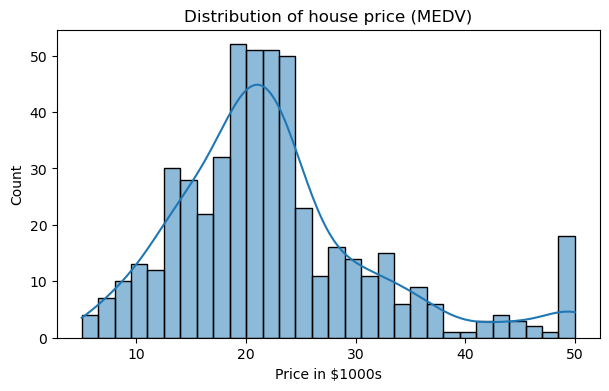

In [6]:
plt.figure(figsize=(7, 4))
sns.histplot(df["MEDV"], bins=30, kde=True)
plt.title("Distribution of house price (MEDV)")
plt.xlabel("Price in $1000s")
plt.show()

In [7]:
print("Houses priced exactly 50:", (df["MEDV"] == 50).sum())
print("Average price:", round(df["MEDV"].mean(), 2))
print("Median price :", df["MEDV"].median())

Houses priced exactly 50: 16
Average price: 22.53
Median price : 21.2


**Observation:** Most houses cost between 15 and 25 (that is $15,000 to $25,000 in this old data).
There is a bunch of houses at exactly 50. The dataset cut off all higher prices at 50, so the real prices of those
houses are unknown. This will make it a little harder for the model at the high end.

### Distribution of all features

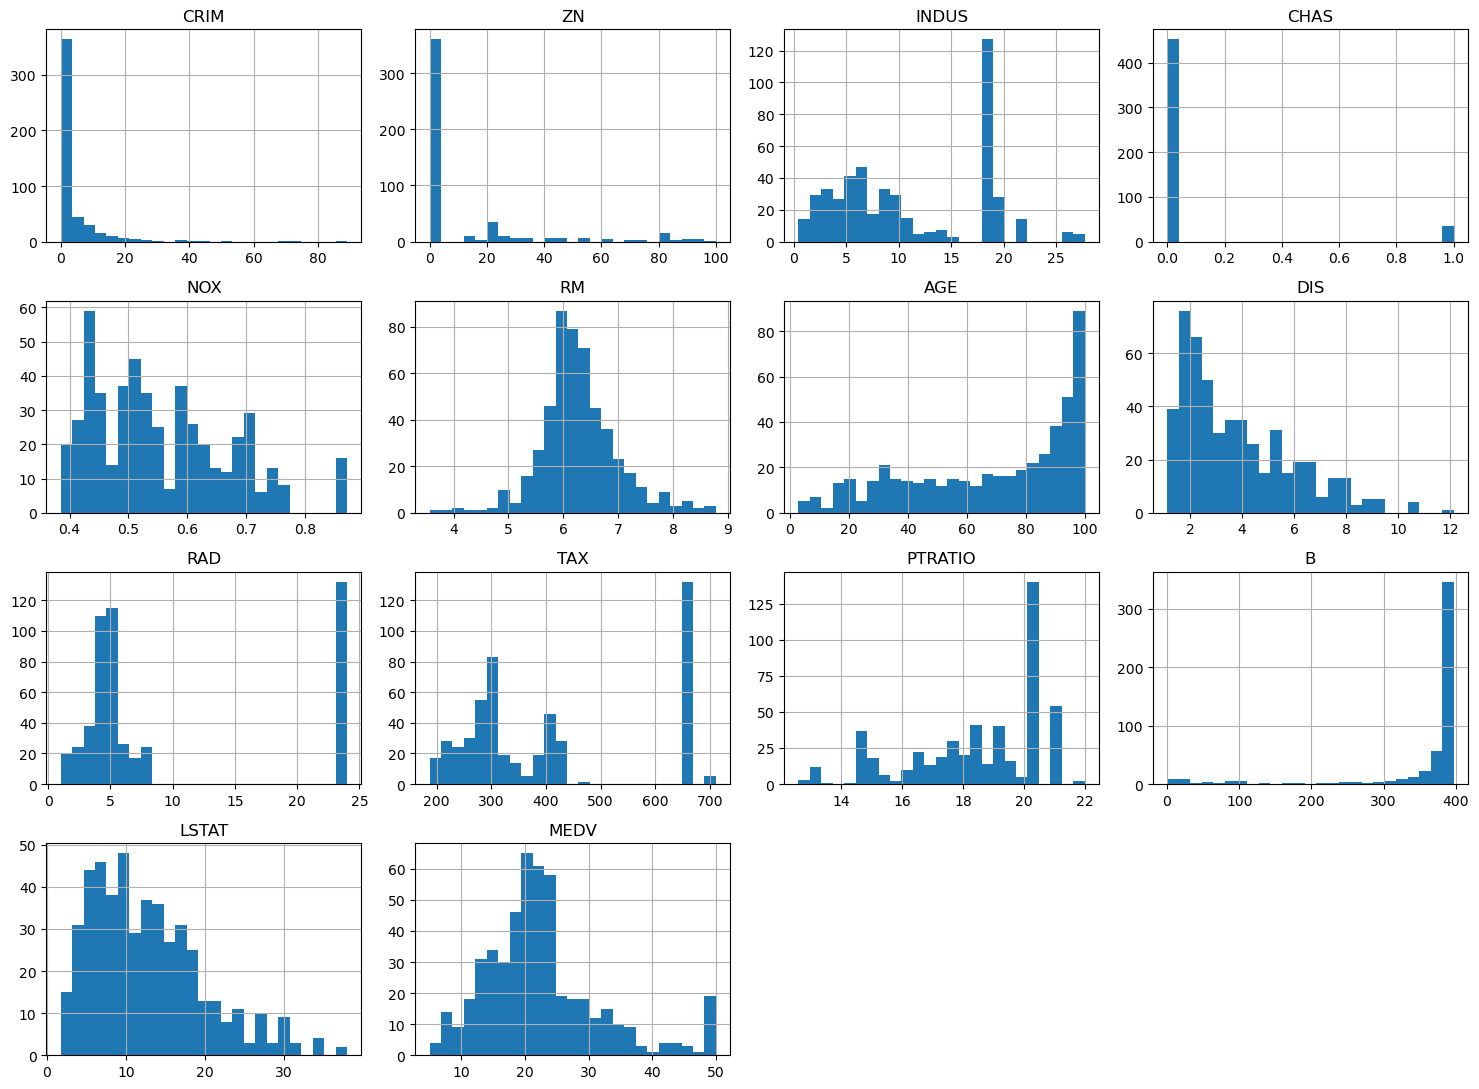

In [8]:
df.hist(figsize=(15, 11), bins=25)
plt.tight_layout()
plt.show()

**Observation:**
- `CRIM` and `ZN` are heavily skewed. Most values are small and a few are very large.
- `CHAS` has only 0 and 1 (a yes/no column).
- `RM` looks like a normal bell curve.

### Outliers (boxplots)

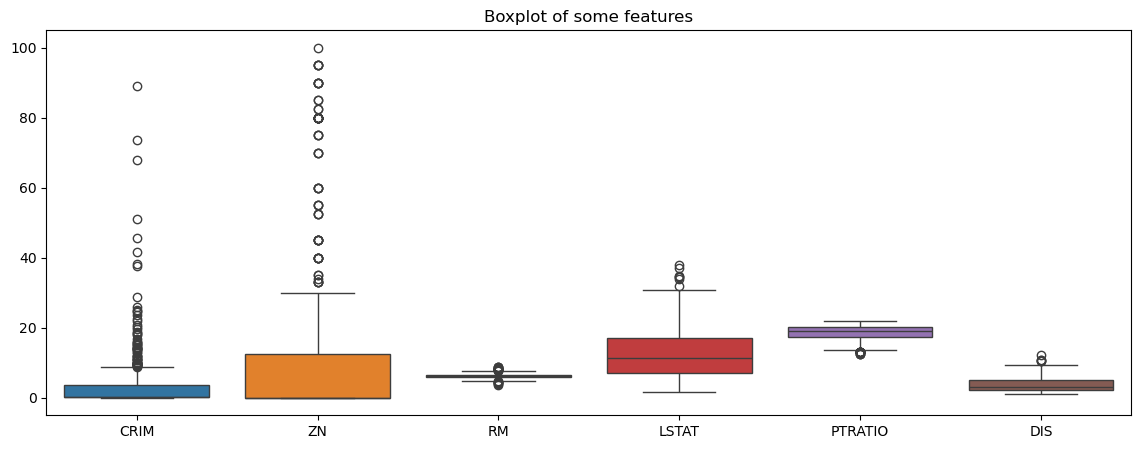

In [9]:
plt.figure(figsize=(14, 5))
sns.boxplot(data=df[["CRIM", "ZN", "RM", "LSTAT", "PTRATIO", "DIS"]])
plt.title("Boxplot of some features")
plt.show()

Dots outside the boxes are outliers. `CRIM` has many of them. We keep them because they are real towns, not mistakes.

### Correlation: which features affect the price?
Correlation is a number between -1 and +1.
- Close to **+1** → when this feature goes up, price goes up
- Close to **-1** → when this feature goes up, price goes down
- Close to **0** → no relation

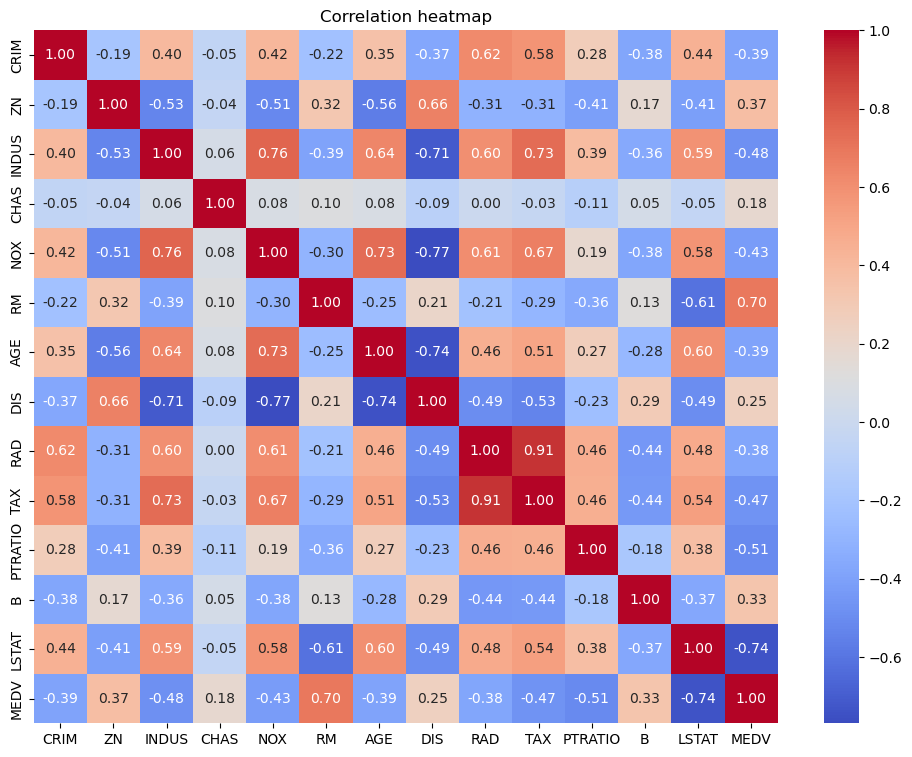

In [10]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

In [11]:
corr_with_price = df.corr()["MEDV"].sort_values(ascending=False)
print(corr_with_price)

MEDV       1.000000
RM         0.695360
ZN         0.373136
B          0.333461
DIS        0.249929
CHAS       0.181391
RAD       -0.381626
CRIM      -0.391363
AGE       -0.394656
NOX       -0.427321
TAX       -0.468536
INDUS     -0.481772
PTRATIO   -0.507787
LSTAT     -0.735822
Name: MEDV, dtype: float64


**Observation:**
- `RM` (rooms) has a strong **positive** correlation with price. Bigger houses cost more.
- `LSTAT` (% lower-income) has a strong **negative** correlation. More lower-income area means lower price.
- `PTRATIO` and `INDUS` are also negative.

Let's see the two strongest ones on a scatter plot.

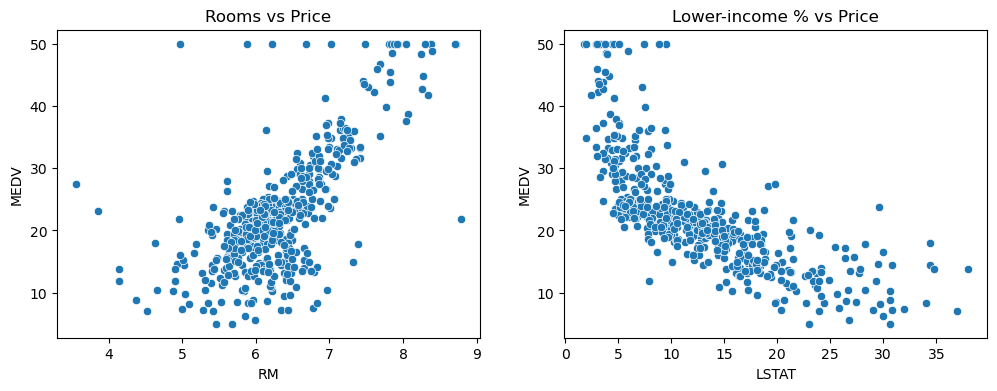

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.scatterplot(x="RM", y="MEDV", data=df, ax=axes[0])
axes[0].set_title("Rooms vs Price")

sns.scatterplot(x="LSTAT", y="MEDV", data=df, ax=axes[1])
axes[1].set_title("Lower-income % vs Price")

plt.show()

## Step 4: Choose Features (X) and Target (y)

- **X** = input features (everything except price)
- **y** = what we want to predict (`MEDV`)

**Note about column `B`:** this column is based on the racial makeup of each town. Using it to predict house prices is
not fair, and this is the reason the Boston dataset was removed from scikit-learn. So we **drop `B`** and
use the other 12 features. (If you want to keep it, just remove `"B"` from the list below.)

In [13]:
X = df.drop(["MEDV", "B"], axis=1)
y = df["MEDV"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print()
print("Features used:", list(X.columns))

X shape: (506, 12)
y shape: (506,)

Features used: ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'LSTAT']


## Step 5: Train / Test Split
We keep 80% of the houses to **train** the model and 20% to **test** it on houses it has never seen.

**Why do we split BEFORE handling missing values and scaling?**
For filling missing values and scaling, we calculate numbers like the median and the mean.
If we calculate them using the full data, the test data secretly influences training. This is called **data leakage**.
So the rule is:
1. Split first
2. Calculate the median/mean from **train data only**
3. Apply the same numbers to the test data

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training houses:", X_train.shape[0])
print("Testing houses :", X_test.shape[0])

Training houses: 404
Testing houses : 102


## Step 6: Handle Missing Data

First, check where the data is missing.

In [15]:
print("Missing values in X_train:")
print(X_train.isnull().sum())
print()
print("Missing values in X_test:")
print(X_test.isnull().sum())

Missing values in X_train:
CRIM       18
ZN         17
INDUS      18
CHAS       16
NOX         0
RM          0
AGE        16
DIS         0
RAD         0
TAX         0
PTRATIO     0
LSTAT      15
dtype: int64

Missing values in X_test:
CRIM       2
ZN         3
INDUS      2
CHAS       4
NOX        0
RM         0
AGE        4
DIS        0
RAD        0
TAX        0
PTRATIO    0
LSTAT      5
dtype: int64


Six columns have missing values: `CRIM, ZN, INDUS, CHAS, AGE, LSTAT`.

### What can we do?
| Option | Problem |
|---|---|
| Delete rows with missing values | We have only 506 rows. We would lose a lot of data. |
| Fill with **mean** | Mean is pulled by outliers (CRIM has huge outliers) |
| Fill with **median** | Middle value, not affected by outliers ✅ |

We will fill with the **median**. For `CHAS` (a 0/1 column) the median is 0, which is the most common value, so that is fine too.

In [16]:
# Fill each column using the MEDIAN OF TRAIN DATA
columns_with_missing = ["CRIM", "ZN", "INDUS", "CHAS", "AGE", "LSTAT"]

for col in columns_with_missing:
    median_value = X_train[col].median()
    print(col, "-> median used:", median_value)

    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

CRIM -> median used: 0.26139
ZN -> median used: 0.0
INDUS -> median used: 8.56
CHAS -> median used: 0.0
AGE -> median used: 76.95
LSTAT -> median used: 10.97


In [17]:
# Check again
print("Total missing in X_train:", X_train.isnull().sum().sum())
print("Total missing in X_test :", X_test.isnull().sum().sum())

Total missing in X_train: 0
Total missing in X_test : 0


## Step 7: Normalization (Scaling)

Look at the ranges of our features:
- `TAX` goes up to 700
- `NOX` is only between 0.4 and 0.9

When features have very different ranges, it is hard to compare them. Scaling puts all features on the same level.

### Standardization (StandardScaler)
Formula: `new value = (value - mean) / standard deviation`

After this, every feature has **mean = 0** and **standard deviation = 1**.

(Another option is MinMaxScaler, which squeezes values between 0 and 1.)

**Before scaling:**

In [18]:
X_train.describe().loc[["mean", "std", "min", "max"]].round(2)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT
mean,3.45,11.02,10.78,0.07,0.56,6.32,68.70,3.81,9.36,404.03,18.32,12.42
std,8.84,23.03,6.72,0.25,0.12,0.71,27.32,2.13,8.59,166.17,2.23,6.97
min,0.01,0.00,0.74,0.00,0.38,3.86,2.90,1.13,1.00,187.00,12.60,1.73
max,88.98,100.00,27.74,1.00,0.87,8.78,100.00,12.13,24.00,711.00,22.00,37.97


In [19]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # learn mean/std from train and apply
X_test_scaled = scaler.transform(X_test)         # only apply on test

# convert back to DataFrame so column names are visible
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print("Scaling done")

Scaling done


**After scaling:** (mean is about 0 and std is about 1 for every column)

In [20]:
X_train_scaled.describe().loc[["mean", "std", "min", "max"]].round(2)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT
mean,0.00,0.00,0.00,0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-0.39,-0.48,-1.49,-0.27,-1.46,-3.46,-2.41,-1.26,-0.97,-1.31,-2.57,-1.54
max,9.69,3.87,2.53,3.66,2.68,3.48,1.15,3.91,1.71,1.85,1.65,3.67


Same rule as before: `fit_transform` on train, only `transform` on test.

**Important:** Linear Regression does not strictly need scaling to give predictions. But scaling makes the
**coefficients comparable** (we will use this in Step 10), and it is required for many other models.

## Step 8: Train the Linear Regression Model

**Simple idea:** Linear Regression draws the best straight line through the data.
For many features, it learns a weight for each feature:

`price = w1 × feature1 + w2 × feature2 + ... + intercept`

Training means finding the weights that make the prediction errors as small as possible.

In [21]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

print("Model trained")

Model trained


## Step 9: Predictions and Evaluation

### Metrics
| Metric | Meaning | Good value |
|---|---|---|
| **MSE** (Mean Squared Error) | Average of (actual - predicted)² | Lower is better |
| **RMSE** | Square root of MSE. Same unit as price. | Lower is better |
| **MAE** | Average of the absolute error | Lower is better |
| **R² score** | How much of the price variation the model explains (1 = perfect, 0 = useless) | Closer to 1 |

MSE squares the errors, so one big mistake is punished a lot. RMSE is easier to understand because it is in the same unit as the price.

In [22]:
y_pred = model.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("Mean Absolute Error (MAE):", round(mae, 2))
print("R2 Score:", round(r2, 4))

Mean Squared Error (MSE): 23.66
Root Mean Squared Error (RMSE): 4.86
Mean Absolute Error (MAE): 3.08
R2 Score: 0.6774


### Is this MSE good or bad?
MSE alone is hard to understand. So we compare it with a **baseline**: a "dumb" model that predicts the same
average price for every house.

In [23]:
baseline_pred = np.full(len(y_test), y_train.mean())
baseline_mse = mean_squared_error(y_test, baseline_pred)

print("Baseline MSE (always predict average):", round(baseline_mse, 2))
print("Our model MSE                        :", round(mse, 2))

Baseline MSE (always predict average): 75.05
Our model MSE                        : 23.66


### Check for overfitting (train score vs test score)

In [24]:
train_pred = model.predict(X_train_scaled)

print("Train R2:", round(r2_score(y_train, train_pred), 4))
print("Test R2 :", round(r2_score(y_test, y_pred), 4))
print()
print("Train MSE:", round(mean_squared_error(y_train, train_pred), 2))
print("Test MSE :", round(mean_squared_error(y_test, y_pred), 2))

Train R2: 0.7324
Test R2 : 0.6774

Train MSE: 23.25
Test MSE : 23.66


**How to read these results**
- The baseline MSE is about **75**. Our model brings it down to about **24**, so the model makes much smaller errors than just guessing the average.
- RMSE is about **4.9**. That means a typical prediction is wrong by about $4,900 (price is in $1000s).
- R² is about **0.68**. The model explains roughly 68% of why house prices differ.
- Train R² (0.73) and test R² (0.68) are close, so the model is **not overfitting**. The score is limited because a straight line cannot catch every pattern in the data.

### Actual price vs Predicted price

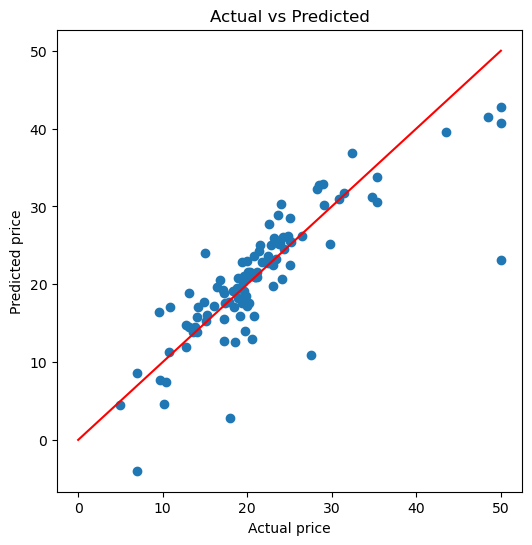

In [25]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred)
plt.plot([0, 50], [0, 50], color="red")      # perfect prediction line
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs Predicted")
plt.show()

The closer the dots are to the red line, the better the predictions.

In [26]:
comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred.round(1)})
comparison["Error"] = (comparison["Actual"] - comparison["Predicted"]).round(1)
comparison.head(10)

,Actual,Predicted,Error
0,23.6,28.9,-5.3
1,32.4,36.8,-4.4
2,13.6,13.8,-0.2
3,22.8,25.1,-2.3
4,16.1,17.2,-1.1
5,20.0,23.0,-3.0
6,17.8,17.7,0.1
7,14.0,13.8,0.2
8,19.6,21.1,-1.5
9,16.8,20.5,-3.7


### Residual plot
Residual = actual - predicted. In a good model the residuals are scattered randomly around 0, with no pattern.

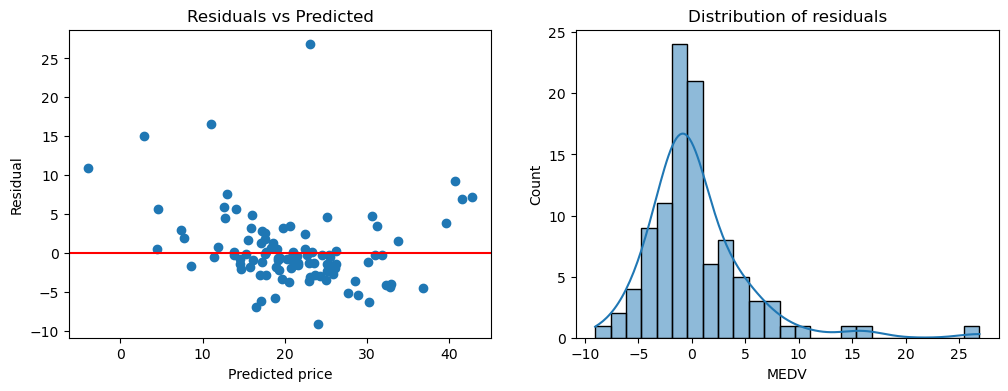

In [27]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_pred, residuals)
axes[0].axhline(0, color="red")
axes[0].set_xlabel("Predicted price")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs Predicted")

sns.histplot(residuals, bins=25, kde=True, ax=axes[1])
axes[1].set_title("Distribution of residuals")

plt.show()

## Step 10: Which Features Matter Most?
Because we scaled the data, we can compare the coefficients directly.
- **Positive** coefficient → this feature increases the price
- **Negative** coefficient → this feature decreases the price
- **Bigger number** → stronger effect

In [28]:
coef_table = pd.DataFrame({"Feature": X_train.columns, "Coefficient": model.coef_})
coef_table = coef_table.sort_values("Coefficient", ascending=False)

print(coef_table.to_string(index=False))
print()
print("Intercept:", round(model.intercept_, 2))

Feature  Coefficient
     RM     3.185620
    RAD     1.654043
   CHAS     0.905876
     ZN     0.657037
  INDUS    -0.288344
    AGE    -0.415198
   CRIM    -1.084091
    TAX    -1.588422
PTRATIO    -1.934182
    NOX    -1.975252
    DIS    -3.238346
  LSTAT    -3.341813

Intercept: 22.8


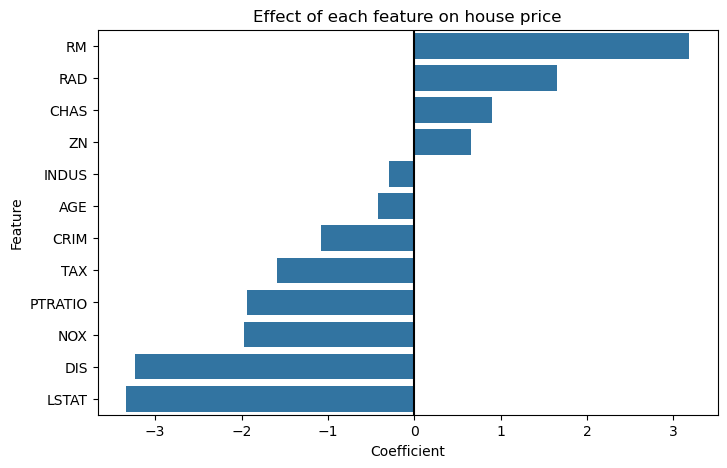

In [29]:
plt.figure(figsize=(8, 5))
sns.barplot(x="Coefficient", y="Feature", data=coef_table)
plt.title("Effect of each feature on house price")
plt.axvline(0, color="black")
plt.show()

**Observation:**
- `RM` (+) pushes the price up. `LSTAT` (-) pushes it down. These match the correlation we saw earlier.
- `DIS` is strongly negative and `RAD` is positive. This looks strange, because their individual correlations were different.
  The reason is that many features are related to each other (for example `RAD` and `TAX`, `NOX` and `DIS`).
  When features are related, Linear Regression shares the effect between them. So read the coefficients as
  "effect while other features are held fixed", not as a simple one-feature effect.

## Step 11: Predict the Price of New Houses
For a new house we must do the same steps as training:
1. Put the values in the same column order
2. Scale them with the **same scaler**
3. Predict

In [30]:
# House 1: bigger house, safe area, low crime
house1 = pd.DataFrame([[0.05, 20, 5, 0, 0.45, 7.5, 40, 5, 4, 270, 15, 4]], columns=X_train.columns)

# House 2: small house, high crime, poor area
house2 = pd.DataFrame([[8.0, 0, 18, 0, 0.70, 5.0, 90, 2, 24, 666, 20, 25]], columns=X_train.columns)

for name, house in [("House 1", house1), ("House 2", house2)]:
    house_scaled = pd.DataFrame(scaler.transform(house), columns=X_train.columns)
    price = model.predict(house_scaled)[0]
    print(name, "-> predicted price: $", round(price * 1000))

House 1 -> predicted price: $ 36385
House 2 -> predicted price: $ 8283


The predicted prices look logical: the bigger house in the safe area costs much more. (Prices are from the 1970s, so they look small today.)

## Step 12: Conclusion

**What we did**
1. Loaded the Boston Housing data (506 houses, 13 features + price)
2. Explored the data: price distribution, feature distributions, outliers, correlation
3. Split into 80% train and 20% test
4. Filled the missing values with the median of the train data
5. Scaled the features with StandardScaler
6. Trained a Linear Regression model
7. Evaluated with MSE, RMSE, MAE and R², and compared with a baseline

**Key points**
- `RM` (more rooms) increases the price. `LSTAT` (more lower-income %) and `DIS` decrease it. These have the biggest effect in the model.
- Final result: **MSE = 23.66, RMSE = 4.86, R² = 0.68** on the test data, compared with a baseline MSE of 75.05.
- We split before filling and scaling, so there is no data leakage.
- Linear Regression is a simple model. It assumes a straight-line relation, so it cannot catch curved patterns.
- Prices are capped at 50, so the model is weaker for the most expensive houses.

**How to improve it further**
- Try Ridge/Lasso, Random Forest or Gradient Boosting and compare the MSE
- Use `log` of price or add polynomial features to catch curved patterns
- Use cross-validation (`cross_val_score`) for a more reliable score
- Remove or reduce outliers and test the effect